# Análise Exploratória: Adequação Docente e Física por Rede

## 1. Configuração e Carregamento

In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from itertools import combinations
from scipy import stats
from statsmodels.stats.oneway import anova_oneway

# Caminhos do projeto
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
INDICADORES = ROOT / "data" / "processed" / "indicadores"
ENEM = ROOT / "data" / "processed" / "enem"
FIGURAS = ROOT / "results" / "figuras"
TABELAS = ROOT / "results" / "tabelas"
FIGURAS.mkdir(parents=True, exist_ok=True)
TABELAS.mkdir(parents=True, exist_ok=True)

# Padrão visual científico (Estilo Artigo Científico / ABNT)
import matplotlib as mpl
sns.set_theme(style="ticks", context="paper")
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": True,
    "font.size": 10.0,
    "axes.titlesize": 10.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.0,
    "xtick.labelsize": 9.0,
    "ytick.labelsize": 9.0,
    "legend.fontsize": 8.8,
    "axes.edgecolor": "#222222",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E0E0E0",
    "grid.linestyle": "--",
    "grid.linewidth": 0.55,
    "grid.alpha": 0.75,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})
ORDEM_REDE = ["Federal", "Privada", "Municipal", "Estadual"]
CORES_REDE = {"Federal": "#0072B2", "Privada": "#009E73", "Municipal": "#E69F00", "Estadual": "#D55E00"}
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_rows(40)


def salvar(fig, nome):
    # Exporta em PDF vetorial (para LaTeX) e PNG 600 DPI (sem textos redundantes de fonte/título)
    stem = Path(nome).stem
    fig.savefig(FIGURAS / f"{stem}.pdf", format="pdf", dpi=600, bbox_inches="tight")
    fig.savefig(FIGURAS / f"{stem}.png", format="png", dpi=600, bbox_inches="tight")
    plt.show()


# Base analítica: escolas pareadas Censo x ENEM com ao menos 10 presentes
base = (
    pl.read_parquet(INDICADORES / "indicadores_ensino_medio_2024.parquet")
    .join(pl.read_parquet(ENEM / "enem_escolas_2024.parquet"), left_on="CO_ENTIDADE", right_on="CO_ESCOLA", how="inner")
    .filter(pl.col("IN_MIN_10_ALUNOS"))
)
print(f"Escolas analisadas: {base.height:,}")

Escolas analisadas: 22,999


## 2. Dissociação entre DSU e Adequação Docente (AFD)

### 2.1 Perfil das Redes de Ensino

In [2]:
# Médias escolares por rede: titulação, AFD, contexto e desempenho
perfil = (
    base.group_by("NO_DEPENDENCIA")
    .agg(
        pl.len().alias("ESCOLAS"),
        pl.col("DSU_MED_DOC_SUPERIOR").mean().round(1).alias("DSU"),
        *[pl.col(f"AFD_MED_CAT_{k}").mean().round(1).alias(f"AFD_G{k}") for k in range(1, 6)],
        pl.col("MEDIA_INSE").mean().round(2).alias("INSE"),
        pl.col("TDI_MED_TOTAL").mean().round(1).alias("TDI"),
        pl.col("ATU_MED_TOTAL").mean().round(1).alias("ATU"),
        pl.col("TX_ABSTENCAO_DIA2").mean().round(1).alias("ABST_DIA2"),
        pl.col("PCT_ACERTO_FISICA").mean().round(1).alias("FISICA"),
        pl.col("PCT_ACERTO_QUIMICA").mean().round(1).alias("QUIMICA"),
        pl.col("PCT_ACERTO_BIOLOGIA").mean().round(1).alias("BIOLOGIA"),
    )
    .sort(pl.col("NO_DEPENDENCIA").replace_strict({r: i for i, r in enumerate(ORDEM_REDE)}))
)
perfil.write_csv(TABELAS / "tab01_perfil_redes.csv")
perfil

NO_DEPENDENCIA,ESCOLAS,DSU,AFD_G1,AFD_G2,AFD_G3,AFD_G4,AFD_G5,INSE,TDI,ATU,ABST_DIA2,FISICA,QUIMICA,BIOLOGIA
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Federal""",596,99.0,81.2,8.2,6.4,3.2,0.9,5.25,15.8,31.4,7.8,35.1,34.7,34.9
"""Privada""",6469,94.9,70.4,1.9,20.8,2.2,4.7,null,5.2,27.8,5.9,37.1,36.7,37.9
"""Municipal""",92,97.6,73.4,0.9,22.6,1.0,2.2,5.36,14.4,27.6,25.4,28.5,29.5,29.6
"""Estadual""",15842,96.8,68.7,1.2,25.2,2.4,2.6,4.88,19.2,29.1,27.9,24.7,27.2,26.4


### 2.2 Gráfico de Composição AFD x DSU

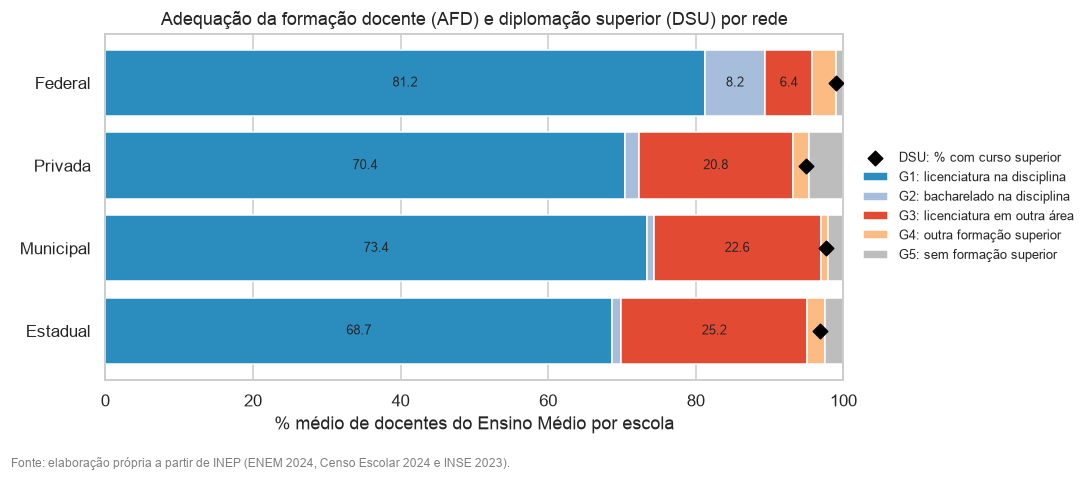

In [3]:
# Barras empilhadas dos grupos AFD com marcador de DSU (Estilo Artigo Científico)
grupos = {
    "AFD_G1": "G1: Licenciatura na disciplina",
    "AFD_G2": "G2: Bacharelado na disciplina",
    "AFD_G3": "G3: Licenciatura em outra área",
    "AFD_G4": "G4: Outra formação superior",
    "AFD_G5": "G5: Sem formação superior",
}
cores_g = ["#1f78b4", "#a6cee3", "#d95f02", "#fdbe85", "#bdbdbd"]
redes = perfil["NO_DEPENDENCIA"].to_list()

fig, ax = plt.subplots(figsize=(6.5, 3.2))
esq = np.zeros(perfil.height)
for (col, rot), cor in zip(grupos.items(), cores_g):
    v = perfil[col].to_numpy()
    ax.barh(redes, v, left=esq, height=0.62, color=cor, label=rot, edgecolor="white", linewidth=0.8)
    for y, (x0, w) in enumerate(zip(esq, v)):
        if w >= 6.0:
            cor_txt = "white" if col in ("AFD_G1", "AFD_G3") else "#111111"
            peso_txt = "bold" if col in ("AFD_G1", "AFD_G3") else "normal"
            ax.text(x0 + w / 2, y, f"{w:.1f}%", ha="center", va="center",
                    fontsize=8.5, color=cor_txt, fontweight=peso_txt)
    esq += v
ax.scatter(perfil["DSU"], redes, marker="D", s=42, color="#111111", edgecolor="white", linewidth=0.7,
           zorder=5, label="DSU: Docentes com ensino superior (%)")
ax.set_xlim(0, 101)
ax.invert_yaxis()
ax.set_xlabel("Proporção média de docentes do Ensino Médio por escola (%)")
ax.set_ylabel("Dependência administrativa")
ax.grid(axis="y", visible=False)
sns.despine(ax=ax, top=True, right=True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.28), ncol=2, frameon=False, columnspacing=1.2, handletextpad=0.5)
salvar(fig, "fig01_composicao_afd_dsu_redes")

## 3. Distribuição em Física e Efeito-Piso (20%)

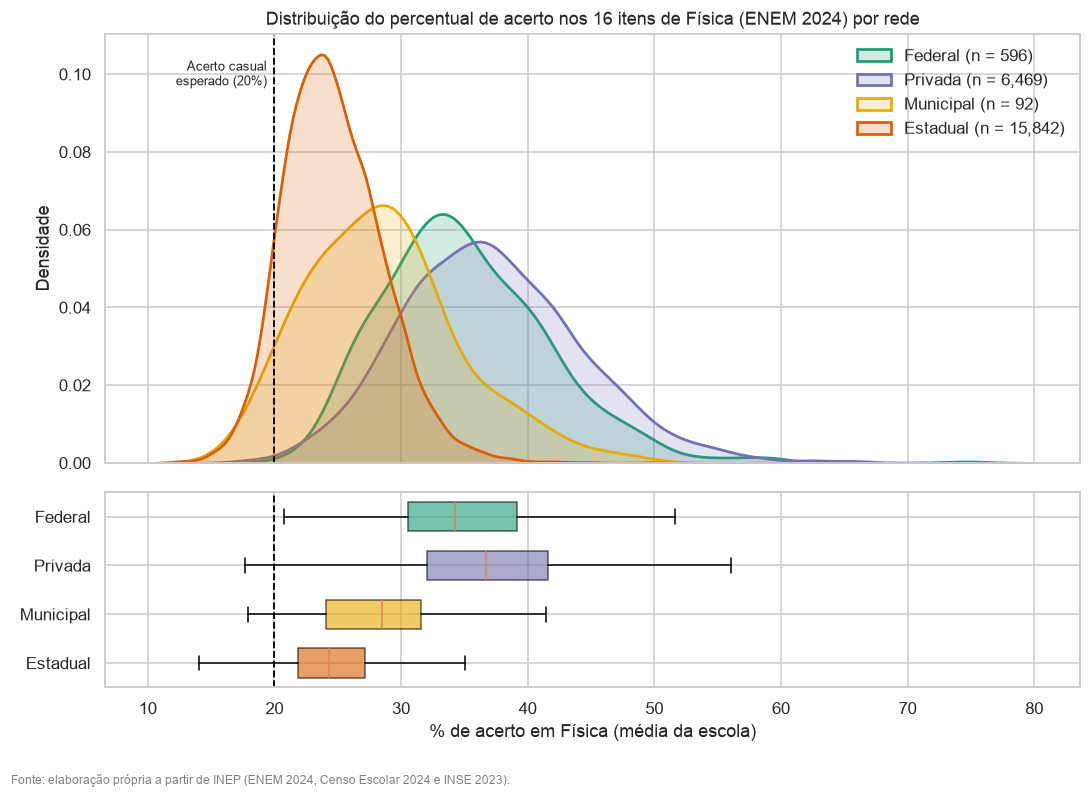

NO_DEPENDENCIA,%_ESCOLAS_ATE_22PCT,MEDIANA_FISICA
str,f64,f64
"""Municipal""",13.0,28.5
"""Privada""",0.9,36.7
"""Federal""",0.2,34.3
"""Estadual""",25.9,24.3


In [4]:
# Densidade (KDE) e boxplot do acerto em Física por rede, com o piso de acerto casual
fis = {r: base.filter(pl.col("NO_DEPENDENCIA") == r)["PCT_ACERTO_FISICA"].to_numpy() for r in ORDEM_REDE}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.4, 4.5), sharex=True, gridspec_kw={"height_ratios": [2.3, 1.0], "hspace": 0.12})
for r, v in fis.items():
    sns.kdeplot(x=v, ax=ax1, color=CORES_REDE[r], fill=True, alpha=0.18, linewidth=1.6, label=f"{r} ($n = {len(v):,d}$)".replace(",", "."))
for ax in (ax1, ax2):
    ax.axvline(20, ls="--", color="#222222", lw=1.1, zorder=4)
ax1.annotate(
    "Acerto casual esperado\n(chute aleatório = 20%)",
    xy=(20, 0.088), xytext=(24.5, 0.094),
    ha="left", va="center", fontsize=8.2, color="#222222",
    bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#DDDDDD", alpha=0.92),
    arrowprops=dict(arrowstyle="->", color="#333333", lw=0.8, connectionstyle="arc3,rad=0.12")
)
ax1.set_ylabel("Densidade de probabilidade")
ax1.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, edgecolor="#CCCCCC")
ax1.text(0.015, 0.94, "(a)", transform=ax1.transAxes, fontweight="bold", fontsize=10, va="top")

bp = ax2.boxplot(list(fis.values()), orientation="horizontal", tick_labels=ORDEM_REDE,
                 patch_artist=True, showfliers=False, widths=0.55,
                 medianprops=dict(color="#111111", linewidth=1.4),
                 whiskerprops=dict(color="#333333", linewidth=0.9),
                 capprops=dict(color="#333333", linewidth=0.9),
                 boxprops=dict(edgecolor="#222222", linewidth=0.8))
for caixa, r in zip(bp["boxes"], ORDEM_REDE):
    caixa.set_facecolor(CORES_REDE[r])
    caixa.set_alpha(0.65)
ax2.invert_yaxis()
ax2.set_xlabel("Taxa média de acerto nos 16 itens de Física por escola (%)")
ax2.set_ylabel("Rede")
ax2.grid(axis="y", visible=False)
ax2.text(0.015, 0.88, "(b)", transform=ax2.transAxes, fontweight="bold", fontsize=10, va="top")
sns.despine(ax=ax1, top=True, right=True)
sns.despine(ax=ax2, top=True, right=True)
salvar(fig, "fig02_densidade_fisica_efeito_piso")

# Proporção de escolas próximas ao piso (até 22% de acerto)
display(base.group_by("NO_DEPENDENCIA").agg(
    (pl.col("PCT_ACERTO_FISICA") <= 22).mean().mul(100).round(1).alias("%_ESCOLAS_ATE_22PCT"),
    pl.col("PCT_ACERTO_FISICA").median().round(1).alias("MEDIANA_FISICA"),
))

## 4. Comparação de Médias entre Redes

### 4.1 Levene (Brown-Forsythe) e ANOVA de Welch

In [5]:
# Heterogeneidade de variâncias e ANOVA robusta a variâncias desiguais
lev = stats.levene(*fis.values(), center="median")
welch = anova_oneway(list(fis.values()), use_var="unequal")
print(f"Levene (Brown-Forsythe): W = {lev.statistic:.1f} | p = {lev.pvalue:.2e}")
print(f"ANOVA de Welch:          F = {welch.statistic:.1f} | gl = ({welch.df_num:.0f}; {welch.df_denom:.1f}) | p = {welch.pvalue:.2e}")
print("Desvio-padrão por rede:", {r: round(float(v.std(ddof=1)), 2) for r, v in fis.items()})

Levene (Brown-Forsythe): W = 978.0 | p = 0.00e+00
ANOVA de Welch:          F = 5999.2 | gl = (3; 393.6) | p = 0.00e+00
Desvio-padrão por rede: {'Federal': 6.61, 'Privada': 7.23, 'Municipal': 5.9, 'Estadual': 4.0}


### 4.2 Pós-teste de Games-Howell

In [6]:
# Comparações par a par sem supor variâncias iguais (distribuição studentized range)
k = len(fis)
linhas = [
    {"TESTE": "Levene (Brown-Forsythe)", "COMPARACAO": "Todas as redes", "ESTATISTICA": lev.statistic, "P_VALOR": lev.pvalue},
    {"TESTE": "ANOVA de Welch", "COMPARACAO": "Todas as redes", "ESTATISTICA": welch.statistic, "P_VALOR": welch.pvalue},
]
for a, b in combinations(ORDEM_REDE, 2):
    x, y = fis[a], fis[b]
    va, vb = x.var(ddof=1) / len(x), y.var(ddof=1) / len(y)
    dif, ep = x.mean() - y.mean(), np.sqrt(va + vb)
    gl = (va + vb) ** 2 / (va ** 2 / (len(x) - 1) + vb ** 2 / (len(y) - 1))
    q = abs(dif) / ep * np.sqrt(2)
    meia = stats.studentized_range.ppf(0.95, k, gl) / np.sqrt(2) * ep
    linhas.append({"TESTE": "Games-Howell", "COMPARACAO": f"{a} - {b}", "ESTATISTICA": q,
                   "DIFERENCA_PP": dif, "IC95_INF": dif - meia, "IC95_SUP": dif + meia,
                   "P_VALOR": stats.studentized_range.sf(q, k, gl)})

tab02 = pl.DataFrame(linhas).with_columns(pl.col(pl.Float64).exclude("P_VALOR").round(2))
tab02.write_csv(TABELAS / "tab02_welch_games_howell_redes.csv")
tab02

TESTE,COMPARACAO,ESTATISTICA,P_VALOR,DIFERENCA_PP,IC95_INF,IC95_SUP
str,str,f64,f64,f64,f64,f64
"""Levene (Brown-Forsythe)""","""Todas as redes""",977.99,0.0,null,null,null
"""ANOVA de Welch""","""Todas as redes""",5999.23,0.0,null,null,null
"""Games-Howell""","""Federal - Privada""",9.95,2.7815e-11,-2.01,-2.74,-1.27
"""Games-Howell""","""Federal - Municipal""",13.85,1.6764e-14,6.58,4.83,8.33
"""Games-Howell""","""Federal - Estadual""",54.03,0.0,10.41,9.71,11.11
"""Games-Howell""","""Privada - Municipal""",19.53,0.0,8.59,6.96,10.22
"""Games-Howell""","""Privada - Estadual""",184.09,0.0,12.42,12.17,12.66
"""Games-Howell""","""Municipal - Estadual""",8.78,9.2121e-8,3.83,2.21,5.44


## 5. Matriz de Correlações Bivariadas

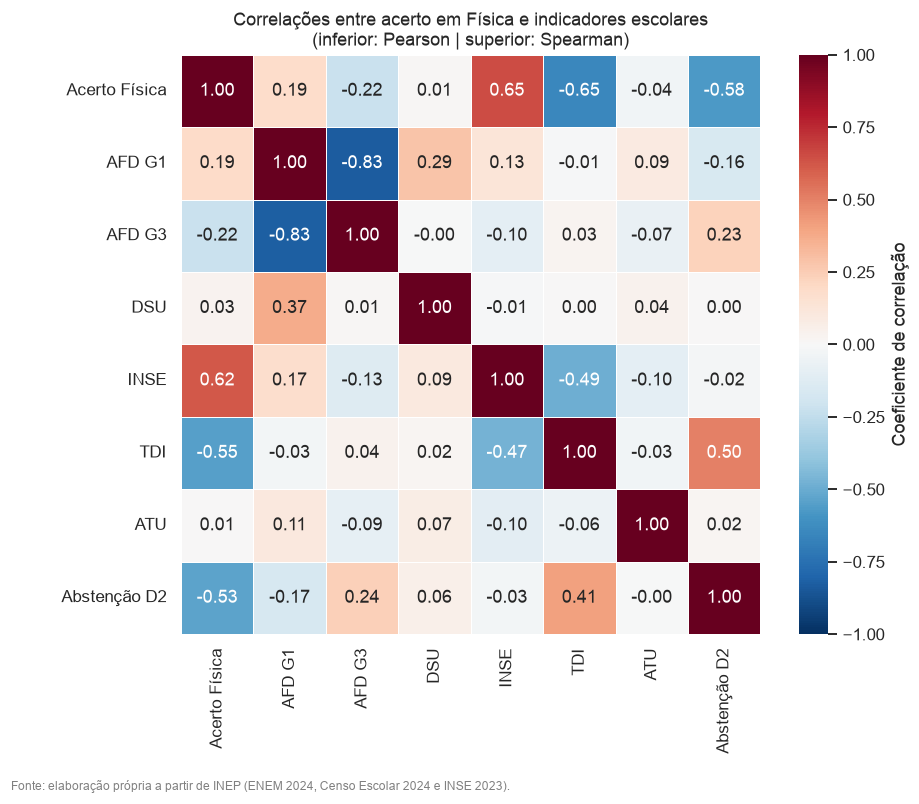

In [7]:
# Pearson (triângulo inferior) e Spearman (superior), com exclusão par a par de nulos
VARS = {
    "PCT_ACERTO_FISICA": "Acerto Física", "AFD_MED_CAT_1": "AFD G1", "AFD_MED_CAT_3": "AFD G3",
    "DSU_MED_DOC_SUPERIOR": "DSU", "MEDIA_INSE": "INSE", "TDI_MED_TOTAL": "TDI",
    "ATU_MED_TOTAL": "ATU", "TX_ABSTENCAO_DIA2": "Abstenção D2",
}
cols = list(VARS)
M = np.eye(len(cols))
for i, a in enumerate(cols):
    for j, b in enumerate(cols):
        if i != j:
            metodo = "pearson" if i > j else "spearman"
            M[i, j] = base.select(a, b).drop_nulls().select(pl.corr(a, b, method=metodo)).item()

fig, ax = plt.subplots(figsize=(5.8, 4.8))
sns.heatmap(M, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=0.6, linecolor="white",
            xticklabels=list(VARS.values()), yticklabels=list(VARS.values()), ax=ax,
            annot_kws={"size": 8.5},
            cbar_kws={"label": "Coeficiente de correlação ($r$ / $\\rho$)", "shrink": 0.82})
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.text(0.5, 1.03, "Triângulo inferior: Pearson ($r$)  |  Triângulo superior: Spearman ($\\rho$)",
        transform=ax.transAxes, ha="center", va="bottom", fontsize=9.0, style="italic", color="#333333")
salvar(fig, "fig03_matriz_correlacao_indicadores")